# Tools & Agents 기초

이 노트북에서는 LangChain의 도구(Tools)와 에이전트(Agents) 개념을 학습합니다.
도구는 모델이 외부 세계와 상호작용할 수 있게 해주며, 에이전트는 도구를 사용하여 복잡한 작업을 수행합니다.

**참고**: 
- [LangChain 공식 문서 - Tools](https://docs.langchain.com/oss/python/langchain/tools)
- [LangChain 공식 문서 - Agents](https://docs.langchain.com/oss/python/langchain/agents)

**실전 예제**: 이 노트북을 학습한 후 `Flask_WebUI/101_Tools_Agent.py`를 실행해보세요.

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()

True

In [2]:
from langchain.chat_models import init_chat_model

# 모델 초기화
model = init_chat_model(
    os.environ["OPENAI_MODEL"],
    model_provider="openai",
    use_responses_api=True,        # Responses API 사용 (Chat Completions에서는 추론 모델의 도구 호출 불가)
    reasoning={"effort": "low"},   # 추론 강도 낮춤 → 실습 속도·비용 절감
)
model

ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7', 'langchain-openai': '1.7.3'}}, profile={'name': 'GPT-6 Luna', 'release_date': '2026-09-22', 'last_updated': '2026-09-22', 'open_weights': False, 'max_input_tokens': 1050000, 'max_output_tokens': 128000, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': False, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True, 'reasoning_effort_levels': ['none', 'low', 'medium', 'high', 'xhigh', 'max'], 'reasoning_effort_default': 'medium', 'mid_conversation_system_messages': True, 'mid_conversation_tools': True}, client=<openai.resources.chat.completions.completions.Completions obje

## Tools & Agents 기초

도구(Tools)와 에이전트(Agents)는 LangChain의 핵심 개념입니다.
도구는 모델이 외부 세계와 상호작용할 수 있게 해주며, 에이전트는 도구를 사용하여 복잡한 작업을 수행합니다.

### 1. 도구 정의 (Tools)

도구(Tools)는 에이전트가 특정 행동을 수행하기 위해 호출하는 구성 요소입니다.
이들은 모델이 명확히 정의된 입력과 출력을 통해 외부 세계와 상호작용할 수 있도록 하여 모델의 기능을 확장합니다.

도구는 호출 가능한 함수(callable function)와 그에 대한 입력 스키마(input schema)를 캡슐화합니다.
이러한 도구들은 호환되는 채팅 모델(chat model)에 전달될 수 있으며, 모델은 도구를 언제, 어떤 인수(argument)로 호출할지 스스로 결정할 수 있습니다.

In [3]:
from langchain.tools import tool

# 가장 간단하게 도구를 만드는 방법은 @tool 데코레이터를 사용하는 것입니다.
# Type hints는 필수입니다. 이들은 도구의 입력 스키마(input schema)를 정의하기 때문입니다.
# 독스트링(docstring)은 모델이 도구의 목적을 이해할 수 있도록 간결하면서도 유용한 정보를 포함해야 합니다.

@tool
def search_db(query: str, limit: int = 10) -> str:
    """검색어(query)에 해당하는 고객 데이터베이스 레코드를 조회합니다.

    Args:
        query: 검색할 키워드 또는 문장
        limit: 반환할 최대 결과 개수
    """
    return f"'{query}'에 대한 검색 결과 {limit}개를 찾았습니다."

# 도구 정보 확인
print("도구 이름:", search_db.name)
print("도구 설명:", search_db.description)

도구 이름: search_db
도구 설명: 검색어(query)에 해당하는 고객 데이터베이스 레코드를 조회합니다.

    Args:
        query: 검색할 키워드 또는 문장
        limit: 반환할 최대 결과 개수


### 2. 고급 스키마 정의

Pydantic 모델이나 JSON 스키마를 사용하여 복잡한 입력을 정의할 수 있습니다.

In [4]:
from pydantic import BaseModel, Field
from langchain_core.tools import tool
import requests

# 입력 데이터 구조 정의 (Pydantic 사용)
class WeatherInput(BaseModel):
    """날씨 질의에 사용할 입력 스키마"""
    latitude: float = Field(description="질의할 지역의 위도를 입력합니다.")
    longitude: float = Field(description="질의할 지역의 경도를 입력합니다.")

# 현재의 온도 가져오기
@tool(args_schema=WeatherInput)
def get_weather(latitude, longitude) -> str:
    """
    제공된 좌표의 현재 기온을 섭씨(Celsius) 단위로 가져옵니다.
    """
    print('get_weather 도구 호출됨')
    try:
        response = requests.get(f"https://api.open-meteo.com/v1/forecast?latitude={latitude}&longitude={longitude}&current=temperature_2m")
        data = response.json()
        temp = data['current']['temperature_2m']
        return f"현재 기온: {temp}°C"
    except Exception as e:
        return f"날씨 정보를 가져오는 중 오류 발생: {e}"

# 서울의 위도, 경도로 테스트
print(get_weather.invoke({'latitude': 37.56667, 'longitude': 126.97806}))

get_weather 도구 호출됨
현재 기온: 8.8°C


### 3. Agent 생성

에이전트(Agents)는 언어 모델과 도구를 결합하여 작업에 대해 추론하고, 사용할 도구를 결정하며, 솔루션을 향해 반복적으로 작업할 수 있는 시스템을 만듭니다.
`create_agent`는 프로덕션에 바로 사용 가능한 에이전트 구현을 제공합니다.
LLM 에이전트는 목표를 달성하기 위해 도구를 반복적으로 실행합니다.

에이전트가 생성되었습니다.
에이전트가 사용할 수 있는 도구: ['search_db', 'get_weather']


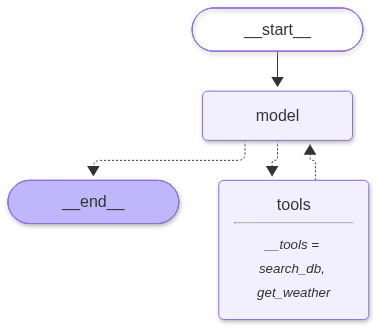

In [5]:
from langchain.agents import create_agent

# 사용 가능한 도구 목록 준비
available_tools = [search_db, get_weather]

# ReAct 에이전트 생성
agent = create_agent(
    model=model,
    tools=available_tools  # Agent가 사용할 도구 목록
)

print("에이전트가 생성되었습니다.")
print(f"에이전트가 사용할 수 있는 도구: {[tool.name for tool in available_tools]}")
agent

### 4. Agent 호출 (Invocation)

에이전트는 State(상태)에 대한 업데이트를 전달하여 호출할 수 있습니다.
모든 에이전트는 상태 안에 메시지들의 시퀀스(sequence of messages)를 포함하고 있으며, 에이전트를 호출하려면 새로운 메시지를 전달하면 됩니다.

In [6]:
# 기본 에이전트 호출 예제
result = agent.invoke(
    {"messages": [
        {'role': 'system', "content": "당신은 도움이 되는 어시스턴트입니다. 주어진 도구를 이용해 답변하세요."},
        {"role": "user", "content": "지금 서울 기온이 몇도인가요?"}
    ]}
)

print("에이전트 응답:")
print(result['messages'][-1].text)

get_weather 도구 호출됨
에이전트 응답:
현재 서울 기온은 **8.8°C**입니다.


## 실습문제: 나만의 도구 에이전트 만들기

본문에서 배운 흐름(도구 정의 → 에이전트 생성 → 호출)을 그대로 적용해 보세요.

1. **@tool 데코레이터**: 할인가를 계산하는 `calc_discount(price: float, discount_percent: float)` 도구를 만드세요.
   타입 힌트와 docstring을 반드시 포함하세요. (1장 참고)
2. **Pydantic 스키마**: `BmiInput(height_cm, weight_kg)` 스키마를 정의하고,
   `@tool(args_schema=BmiInput)`로 BMI를 계산하는 `calc_bmi` 도구를 만드세요.
   BMI = 체중(kg) ÷ (키(m))² (2장 참고)
3. **에이전트 생성 + 호출**: 두 도구로 에이전트를 만들고,
   두 도구가 **모두** 필요한 복합 질문(예: "키 175cm 몸무게 70kg의 BMI와, 50,000원 상품의 20% 할인가를 알려줘")을 던져
   도구 호출을 확인하세요. (3~4장 참고)
